# Flavor Change Decomposition: Atomic Strategic Moves in LLM Decision-Making

Decomposes multi-flavor change vectors into sparse combinations of learned
**atomic strategic moves** using dictionary learning.

**Motivation:** each flavor change event modifies ~6.6 flavors on average —
these are *superpositions* of multiple independent strategic adjustments.
HDBSCAN clustering (see `flavor_change_clusters.ipynb`) treats compound
vectors as atomic, assigning only 7.9% of events to clusters. Dictionary
learning instead learns a set of K basis vectors ("atoms") and represents
**every** event as a sparse weighted combination.

Pipeline:
1. **Data loading** — same pipeline as `flavor_change_clusters.ipynb`
2. **Exploratory PCA** — variance explained to guide choice of K
3. **Dictionary learning** — MiniBatchDictionaryLearning with K and α selection
4. **Atom interpretation** — visualize each atom's flavor loadings, assign names
5. **Event decomposition** — show how events decompose into atom combinations
6. **Validation** — reconstruction error, sparsity, comparison to clustering
7. **Effectiveness** — which atoms correlate with improved win probability
8. **Cross-analysis** — atom activation by player type, game phase, strategy
9. **Export** — atom dictionary + per-event sparse codes

In [13]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA, MiniBatchDictionaryLearning
from sklearn.preprocessing import StandardScaler

from shared.plot_utilities import (
    setup_notebook_display,
    load_turn_data,
    forward_fill_strategy,
    detect_all_flavor_changes,
    compute_post_pivot_win_prob,
    classify_pivots
)

setup_notebook_display(figsize=(14, 6))

In [14]:
# Load data, merge win-probability predictions, filter to LLM players
df = load_turn_data("../turn_data.csv", exclude_non_llm=True)
pred = pd.read_csv("../models/output/attention_mlp_predictions.csv")
df = df.merge(
    pred[["game_id", "player_id", "turn", "predicted_win_probability"]],
    on=["game_id", "player_id", "turn"],
    how="left",
)
df = df[df["player_type"] != "Vanilla"].copy()
df_sorted = df.sort_values(["game_id", "player_id", "turn"])
forward_fill_strategy(df_sorted)

# Detect ALL flavor changes (not just strategy pivots)
changes, flavor_cols = detect_all_flavor_changes(df_sorted)
delta_cols = [f"{c}_delta" for c in flavor_cols]
flavor_short = [c.replace("flavor_", "") for c in flavor_cols]

print(f"LLM turns:                {len(df_sorted):,}")
print(f"Flavor change events:     {len(changes):,}")
print(f"  ({len(changes)/len(df_sorted)*100:.1f}% of all turns)")
print(f"Mean flavors changed/event: {changes['n_flavors_changed'].mean():.1f}")

d:\Cache\Onedrive - Arizona\OneDrive - University of Arizona\Vox Deorum\nlp-2026-tiny-4player\analysis\behaviors\..\plot_utilities.py:829: DtypeWarning: Columns (71) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


✓ Loaded turn data: 1039896 rows
✓ Filters applied: exclude_non_llm=True
✓ Unique conditions: 13
✓ Unique player types: 15
✓ Turn range: 0 - 500
✓ Unique civilizations: 43

Player Type Distribution:
  Vanilla: 330508 rows (31.8%)
  GLM-4.7-Simple: 75725 rows (7.3%)
  GLM-4.7-Briefed: 75725 rows (7.3%)
  Kimi-K2.5-Simple: 71134 rows (6.8%)
  Kimi-K2.5-Briefed: 71134 rows (6.8%)
  GPT-OSS-120B-Briefed: 65948 rows (6.3%)
  GPT-OSS-120B-Simple: 65948 rows (6.3%)
  Minimax-M2.5-Simple: 50112 rows (4.8%)
  Minimax-M2.5-Briefed: 50112 rows (4.8%)
  Deepseek-3.2-Briefed: 49080 rows (4.7%)
  Deepseek-3.2-Simple: 49080 rows (4.7%)
  Qwen-3.5-Briefed: 31503 rows (3.0%)
  Qwen-3.5-Simple: 31503 rows (3.0%)
  Sonnet-4.5-Briefed: 11192 rows (1.1%)
  Sonnet-4.5-Simple: 11192 rows (1.1%)

Condition Distribution:
  2026-deepseek-v-kimi2-v-glm-standard: 281688 rows (27.1%)
  2026-oss-v-glm-standard: 223776 rows (21.5%)
  2026-qwen-v-kimi2-v-minimax-standard: 132024 rows (12.7%)
  2026-oss-v-qwen-v-minim

In [15]:
# Split single vs multi-flavor; compute effectiveness for all changes
single = changes[changes["n_flavors_changed"] == 1].copy()
multi = changes[changes["n_flavors_changed"] >= 2].copy()

print(f"Single-flavor events: {len(single):>8,} ({len(single)/len(changes):.1%})")
print(f"Multi-flavor events:  {len(multi):>8,} ({len(multi)/len(changes):.1%})")
print(f"Total:                {len(changes):>8,}")

# Effectiveness: win prob before vs weighted-average after (50-turn window)
changes["before_prob"] = changes["predicted_win_probability"]
changes["after_prob"] = compute_post_pivot_win_prob(changes, df_sorted, window=50)
changes["win_prob_delta"] = changes["after_prob"] - changes["before_prob"]
classify_pivots(changes, threshold=0.05)

for col in ["before_prob", "after_prob", "win_prob_delta", "impact_class"]:
    multi[col] = changes.loc[multi.index, col]

print(f"\nMulti-flavor events with win_prob_delta: "
      f"{multi['win_prob_delta'].notna().sum():,} / {len(multi):,}")

Single-flavor events:   36,423 (11.2%)
Multi-flavor events:   289,642 (88.8%)
Total:                 326,065

Multi-flavor events with win_prob_delta: 289,338 / 289,642


## Section 1: Exploratory PCA — Variance Structure

How much of the variance in multi-flavor delta vectors is captured by the
top principal components? This guides the choice of K for dictionary learning.

We standardize (zero-mean, unit-variance per feature) rather than L2-normalize:
L2-normalization discards magnitude, but how *much* a flavor changes matters.
Standardization prevents high-variance flavors from dominating the decomposition.

Data matrix: 289,642 events × 34 flavors


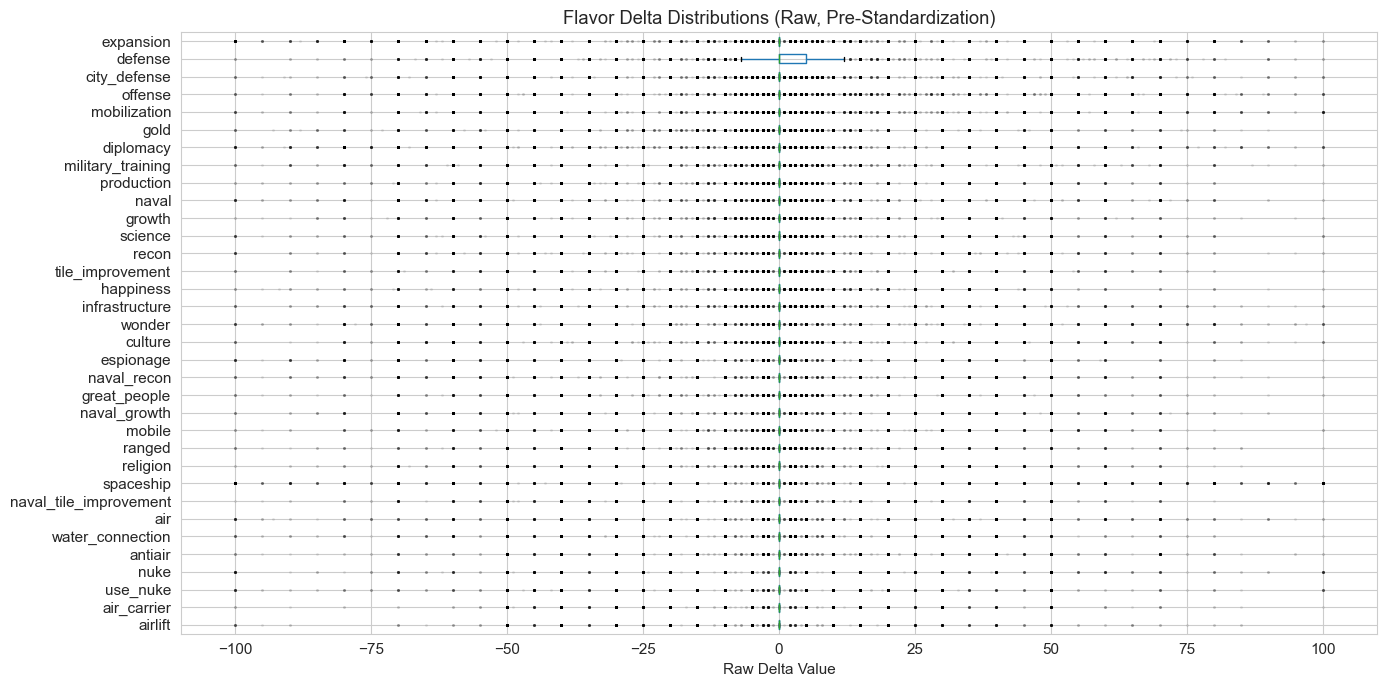


Per-flavor std (raw deltas), top 10:
                  expansion: 11.16
                    defense: 7.83
                    offense: 7.34
                  diplomacy: 7.22
               mobilization: 7.15
               city_defense: 6.95
                      naval: 6.63
          military_training: 6.48
                       gold: 6.23
                     wonder: 6.22


In [16]:
# Prepare the data matrix and standardize
X_raw = multi[delta_cols].fillna(0).values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

print(f"Data matrix: {X_scaled.shape[0]:,} events × {X_scaled.shape[1]} flavors")

# Delta magnitude distribution across flavors (motivates standardization)
fig, ax = plt.subplots(figsize=(14, 7))
raw_df = pd.DataFrame(X_raw, columns=flavor_short)
order = raw_df.abs().mean().sort_values(ascending=False).index
raw_df[order].boxplot(ax=ax, vert=False, flierprops=dict(markersize=1, alpha=0.1))
ax.set_xlabel("Raw Delta Value")
ax.set_title("Flavor Delta Distributions (Raw, Pre-Standardization)")
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print("\nPer-flavor std (raw deltas), top 10:")
stds = pd.Series(X_raw.std(axis=0), index=flavor_short).sort_values(ascending=False)
for name, val in stds.head(10).items():
    print(f"  {name:>25s}: {val:.2f}")

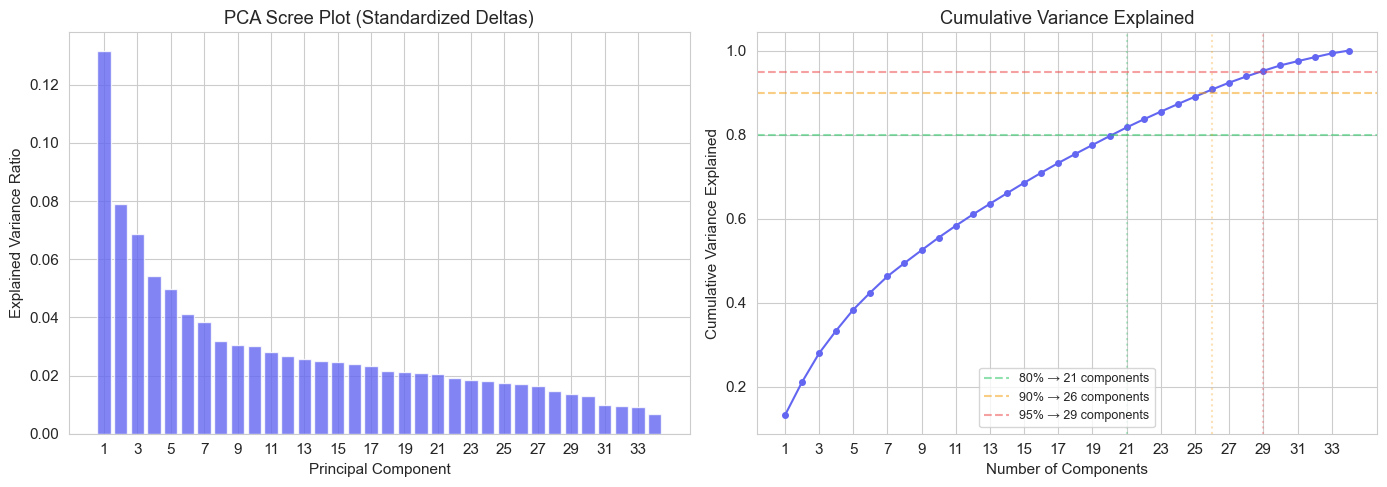

  80% variance → 21 components
  90% variance → 26 components
  95% variance → 29 components

This suggests K ≥ 26 for dictionary learning.
Dictionary learning can use K > PCA rank (overcomplete) since sparsity
constrains the codes, discovering specialized atoms PCA would merge.


In [17]:
# PCA on standardized deltas — scree plot and cumulative variance
pca_full = PCA(n_components=34, random_state=42)
pca_full.fit(X_scaled)

var_ratio = pca_full.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
ax1.bar(range(1, 35), var_ratio, color="#6366F1", alpha=0.8, edgecolor="white")
ax1.set_xlabel("Principal Component")
ax1.set_ylabel("Explained Variance Ratio")
ax1.set_title("PCA Scree Plot (Standardized Deltas)")
ax1.set_xticks(range(1, 35, 2))

# Cumulative variance
ax2.plot(range(1, 35), cum_var, "o-", color="#6366F1", markersize=4)
for threshold, color, ls in [(0.80, "#22C55E", "--"), (0.90, "#F59E0B", "--"),
                              (0.95, "#EF4444", "--")]:
    k_needed = np.searchsorted(cum_var, threshold) + 1
    ax2.axhline(threshold, color=color, ls=ls, alpha=0.5,
                label=f"{threshold:.0%} → {k_needed} components")
    ax2.axvline(k_needed, color=color, ls=":", alpha=0.3)
ax2.set_xlabel("Number of Components")
ax2.set_ylabel("Cumulative Variance Explained")
ax2.set_title("Cumulative Variance Explained")
ax2.legend(fontsize=9)
ax2.set_xticks(range(1, 35, 2))

plt.tight_layout()
plt.show()

# Summary
for t in [0.80, 0.90, 0.95]:
    k = np.searchsorted(cum_var, t) + 1
    print(f"  {t:.0%} variance → {k} components")
print(f"\nThis suggests K ≥ {np.searchsorted(cum_var, 0.90) + 1} for dictionary learning."
      f"\nDictionary learning can use K > PCA rank (overcomplete) since sparsity"
      f"\nconstrains the codes, discovering specialized atoms PCA would merge.")

## Section 2: Dictionary Learning — Selecting K and α

**MiniBatchDictionaryLearning** learns K atoms (basis vectors) and represents
each event as a sparse linear combination: `x ≈ Σ αₖ · atomₖ`.

- **K** (n_components) = number of atoms = vocabulary size of strategic moves
- **α** (alpha) = L1 sparsity penalty on codes. Higher α → fewer active atoms per event

We sweep K first with fixed α=1.0, then tune α at the chosen K.
Target: **2–4 active atoms per event** (matching the intuition that each event
combines a handful of independent strategic adjustments).

In [ ]:
# --- K sweep: reconstruction error, sparsity, and dead atoms vs K ---
K_CANDIDATES = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120]
ALPHA_FIXED = 1.0
DEAD_THRESHOLD = 0.01  # atom activating < 1% of events is "dead"

k_results = []
for K in K_CANDIDATES:
    dl = MiniBatchDictionaryLearning(
        n_components=K,
        alpha=ALPHA_FIXED,
        batch_size=1024,
        max_iter=200,
        random_state=42,
        transform_algorithm="lasso_lars",
    )
    dl.fit(X_scaled)
    codes = dl.transform(X_scaled)
    recon = codes @ dl.components_
    mse = np.mean((X_scaled - recon) ** 2)
    active = np.abs(codes) >= 1e-6
    sparsity = 1.0 - active.mean()
    mean_active = active.sum(axis=1).mean()
    per_atom_freq = active.mean(axis=0)
    n_dead = int((per_atom_freq < DEAD_THRESHOLD).sum())

    k_results.append({
        "K": K, "MSE": mse, "sparsity": sparsity,
        "mean_active": mean_active, "n_dead": n_dead,
    })
    dead_flag = f"  ⚠ {n_dead} dead" if n_dead else ""
    print(f"  K={K:>2d}  MSE={mse:.4f}  sparsity={sparsity:.1%}  "
          f"mean_active={mean_active:.1f}  dead={n_dead}{dead_flag}")

k_df = pd.DataFrame(k_results)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

ax1.plot(k_df["K"], k_df["MSE"], "o-", color="#6366F1", markersize=6)
ax1.set_xlabel("K (number of atoms)")
ax1.set_ylabel("Reconstruction MSE")
ax1.set_title("Reconstruction Error vs K")
ax1.grid(alpha=0.3)

ax2.plot(k_df["K"], k_df["mean_active"], "s-", color="#F59E0B", markersize=6)
ax2.axhspan(2, 4, alpha=0.1, color="#22C55E", label="Target: 2–4 active")
ax2.set_xlabel("K (number of atoms)")
ax2.set_ylabel("Mean Active Atoms per Event")
ax2.set_title("Sparsity vs K")
ax2.legend()
ax2.grid(alpha=0.3)

bar_colors = ["#EF4444" if d > 0 else "#22C55E" for d in k_df["n_dead"]]
ax3.bar(k_df["K"], k_df["n_dead"], color=bar_colors, alpha=0.8, width=1.5)
ax3.set_xlabel("K (number of atoms)")
ax3.set_ylabel("Dead Atoms (< 1% activation)")
ax3.set_title("Dead Atom Count vs K")
ax3.set_xticks(k_df["K"])
ax3.grid(alpha=0.3, axis="y")

plt.suptitle(f"K Sweep (α={ALPHA_FIXED})", fontsize=13)
plt.tight_layout()
plt.show()

  K=10  MSE=0.5374  sparsity=82.9%  mean_active=1.7  dead=0
  K=20  MSE=0.3472  sparsity=85.4%  mean_active=2.9  dead=0
  K=30  MSE=0.2269  sparsity=87.0%  mean_active=3.9  dead=0
  K=40  MSE=0.1770  sparsity=90.1%  mean_active=4.0  dead=0
  K=50  MSE=0.1535  sparsity=92.0%  mean_active=4.0  dead=0
  K=60  MSE=0.1469  sparsity=92.9%  mean_active=4.2  dead=0
  K=70  MSE=0.1393  sparsity=93.8%  mean_active=4.3  dead=0
  K=80  MSE=0.1355  sparsity=94.4%  mean_active=4.5  dead=0
  K=90  MSE=0.1305  sparsity=94.8%  mean_active=4.7  dead=1  ⚠ 1 dead
  K=100  MSE=0.1279  sparsity=95.3%  mean_active=4.7  dead=0
  K=110  MSE=0.1244  sparsity=95.7%  mean_active=4.8  dead=4  ⚠ 4 dead


KeyboardInterrupt: 

In [19]:
K_CHOSEN = 80

  α=0.50   MSE=0.0454  mean_active=8.1  median_active=7
  α=1.00   MSE=0.1355  mean_active=4.5  median_active=4
  α=1.25   MSE=0.1814  mean_active=3.5  median_active=3
  α=1.50   MSE=0.2271  mean_active=2.8  median_active=2
  α=1.75   MSE=0.2707  mean_active=2.2  median_active=1
  α=2.00   MSE=0.3092  mean_active=1.7  median_active=1


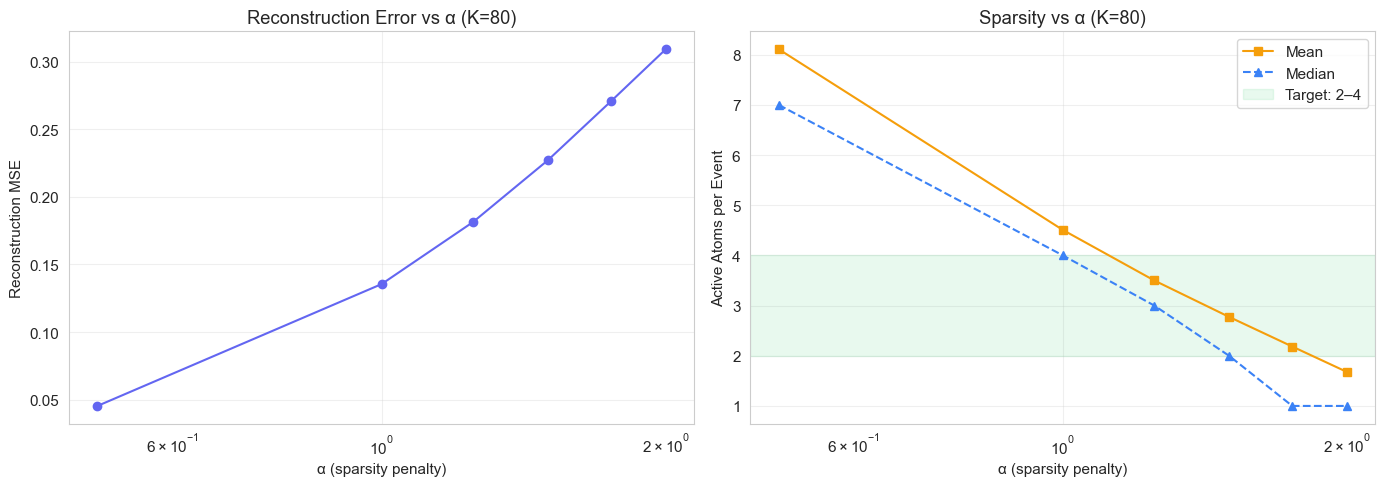

In [20]:
# --- Alpha sweep at chosen K ---
ALPHA_CANDIDATES = [0.5, 1.0, 1.25, 1.5, 1.75, 2.0]

alpha_results = []
for alpha in ALPHA_CANDIDATES:
    dl = MiniBatchDictionaryLearning(
        n_components=K_CHOSEN,
        alpha=alpha,
        batch_size=1024,
        max_iter=200,
        random_state=42,
        transform_algorithm="lasso_lars",
    )
    dl.fit(X_scaled)
    codes = dl.transform(X_scaled)
    recon = codes @ dl.components_
    mse = np.mean((X_scaled - recon) ** 2)
    active = np.abs(codes) >= 1e-6
    mean_active = active.sum(axis=1).mean()
    median_active = np.median(active.sum(axis=1))

    alpha_results.append({
        "alpha": alpha, "MSE": mse,
        "mean_active": mean_active, "median_active": median_active,
    })
    print(f"  α={alpha:<5.2f}  MSE={mse:.4f}  "
          f"mean_active={mean_active:.1f}  median_active={median_active:.0f}")

alpha_df = pd.DataFrame(alpha_results)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(alpha_df["alpha"], alpha_df["MSE"], "o-", color="#6366F1", markersize=6)
ax1.set_xlabel("α (sparsity penalty)")
ax1.set_ylabel("Reconstruction MSE")
ax1.set_title(f"Reconstruction Error vs α (K={K_CHOSEN})")
ax1.set_xscale("log")
ax1.grid(alpha=0.3)

ax2.plot(alpha_df["alpha"], alpha_df["mean_active"], "s-", color="#F59E0B",
         markersize=6, label="Mean")
ax2.plot(alpha_df["alpha"], alpha_df["median_active"], "^--", color="#3B82F6",
         markersize=6, label="Median")
ax2.axhspan(2, 4, alpha=0.1, color="#22C55E", label="Target: 2–4")
ax2.set_xlabel("α (sparsity penalty)")
ax2.set_ylabel("Active Atoms per Event")
ax2.set_title(f"Sparsity vs α (K={K_CHOSEN})")
ax2.set_xscale("log")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [23]:
ALPHA_CHOSEN = 1

## Section 3: Final Model and Atom Interpretation

Fit the final dictionary with more iterations, then visualize each atom's
flavor loadings. Atoms are converted back to the original (unscaled) delta
space for interpretability: each atom vector shows the raw flavor changes
that one unit of activation contributes.

In [24]:
# --- Final dictionary learning fit ---
print(f"Fitting final model: K={K_CHOSEN}, α={ALPHA_CHOSEN:.2f}, max_iter=1000")
dl_final = MiniBatchDictionaryLearning(
    n_components=K_CHOSEN,
    alpha=ALPHA_CHOSEN,
    batch_size=1024,
    max_iter=1000,
    random_state=42,
    transform_algorithm="lasso_lars",
)
dl_final.fit(X_scaled)

codes = dl_final.transform(X_scaled)        # (N, K) sparse codes
atoms_scaled = dl_final.components_          # (K, 34) atoms in scaled space

# Convert atoms to original delta scale for interpretation
# In scaled space: x_scaled = (x_raw - mean) / scale
# An atom in scaled space contributes: atom_scaled * scale in raw space
atoms_orig = atoms_scaled * scaler.scale_[np.newaxis, :]

# Summary stats
recon = codes @ atoms_scaled
mse = np.mean((X_scaled - recon) ** 2)
active = np.abs(codes) >= 1e-6
mean_active = active.sum(axis=1).mean()
sparsity = 1.0 - active.mean()

print(f"\nFinal model summary:")
print(f"  K = {K_CHOSEN}")
print(f"  α = {ALPHA_CHOSEN:.2f}")
print(f"  Reconstruction MSE = {mse:.4f}")
print(f"  Code sparsity = {sparsity:.1%} zeros")
print(f"  Mean active atoms/event = {mean_active:.1f}")
print(f"  Median active atoms/event = {np.median(active.sum(axis=1)):.0f}")

Fitting final model: K=80, α=1.00, max_iter=1000

Final model summary:
  K = 80
  α = 1.00
  Reconstruction MSE = 0.1355
  Code sparsity = 94.4% zeros
  Mean active atoms/event = 4.5
  Median active atoms/event = 4


In [ ]:
# --- Auto-name atoms from their top flavor loadings ---
def name_atom(atom_vec, names, n_top=3):
    """Generate a short interpretable name from top-loaded flavors."""
    abs_vals = np.abs(atom_vec)
    top_idx = np.argsort(abs_vals)[::-1][:n_top]
    parts = []
    for i in top_idx:
        sign = "+" if atom_vec[i] > 0 else "\u2212"
        parts.append(f"{sign}{names[i]}")
    return " / ".join(parts)

# Reorder atoms by activation frequency (most common = Atom 0)
activation_freq = (np.abs(codes) >= 1e-6).mean(axis=0)
order = np.argsort(activation_freq)[::-1]

codes = codes[:, order]
atoms_scaled = atoms_scaled[order]
atoms_orig = atoms_orig[order]
activation_freq = activation_freq[order]

# Interpretive names for the 30 atoms (verb-phrase descriptions of strategic shift)
ATOM_INTERPRETIVE_NAMES = [
    "Stand Down Nuclear & Air",              # 0
    "Neglect Civilian Development",           # 1
    "Mobilize for Total War",                 # 2
    "Fortify Land, Neglect Seas",             # 3
    "Pivot from Offense to Defense",          # 4
    "Push for the Space Race",                # 5
    "Build Infrastructure, Cut Wonders & Culture",  # 6
    "Improve Tiles, Defund Research & Diplomacy",   # 7
    "Explore & Expand",                       # 8
    "Build Conventional Air Power",           # 9
    "Expand Aggressively",                    # 10
    "Militarize the Fleet",                   # 11
    "Sacrifice Happiness for Production",     # 12
    "Slash Religion, Culture & Diplomacy",    # 13
    "Withdraw Intelligence Operations",       # 14
    "Stand Down Ground Forces",               # 15
    "Halt Production, Go on Offense",         # 16
    "Invest in Research over Commerce",       # 17
    "Abandon the Seas",                       # 18
    "Pivot to Diplomacy",                     # 19
    "Rush Wonders",                           # 20
    "Grow Population Rapidly",                # 21
    "Turtle Up & Invest in Culture",          # 22
    "Redirect Culture to Science & Military", # 23
    "Shift to Air Support & Transport",       # 24
    "Mass-Produce Untrained Units",           # 25
    "Urbanize over Rural Development",        # 26
    "Mobilize for Defense",                   # 27
    "Lower City Air Defenses",               # 28
    "Build Up the Navy",                      # 29
]

if K_CHOSEN == len(ATOM_INTERPRETIVE_NAMES):
    atom_names = ATOM_INTERPRETIVE_NAMES
else:
    atom_names = [name_atom(atoms_orig[k], flavor_short) for k in range(K_CHOSEN)]

print("Atoms (sorted by activation frequency, Atom 0 = most common):\n")
for k in range(K_CHOSEN):
    print(f"  Atom {k:>2d}  ({activation_freq[k]:.1%} active)  {atom_names[k]}")

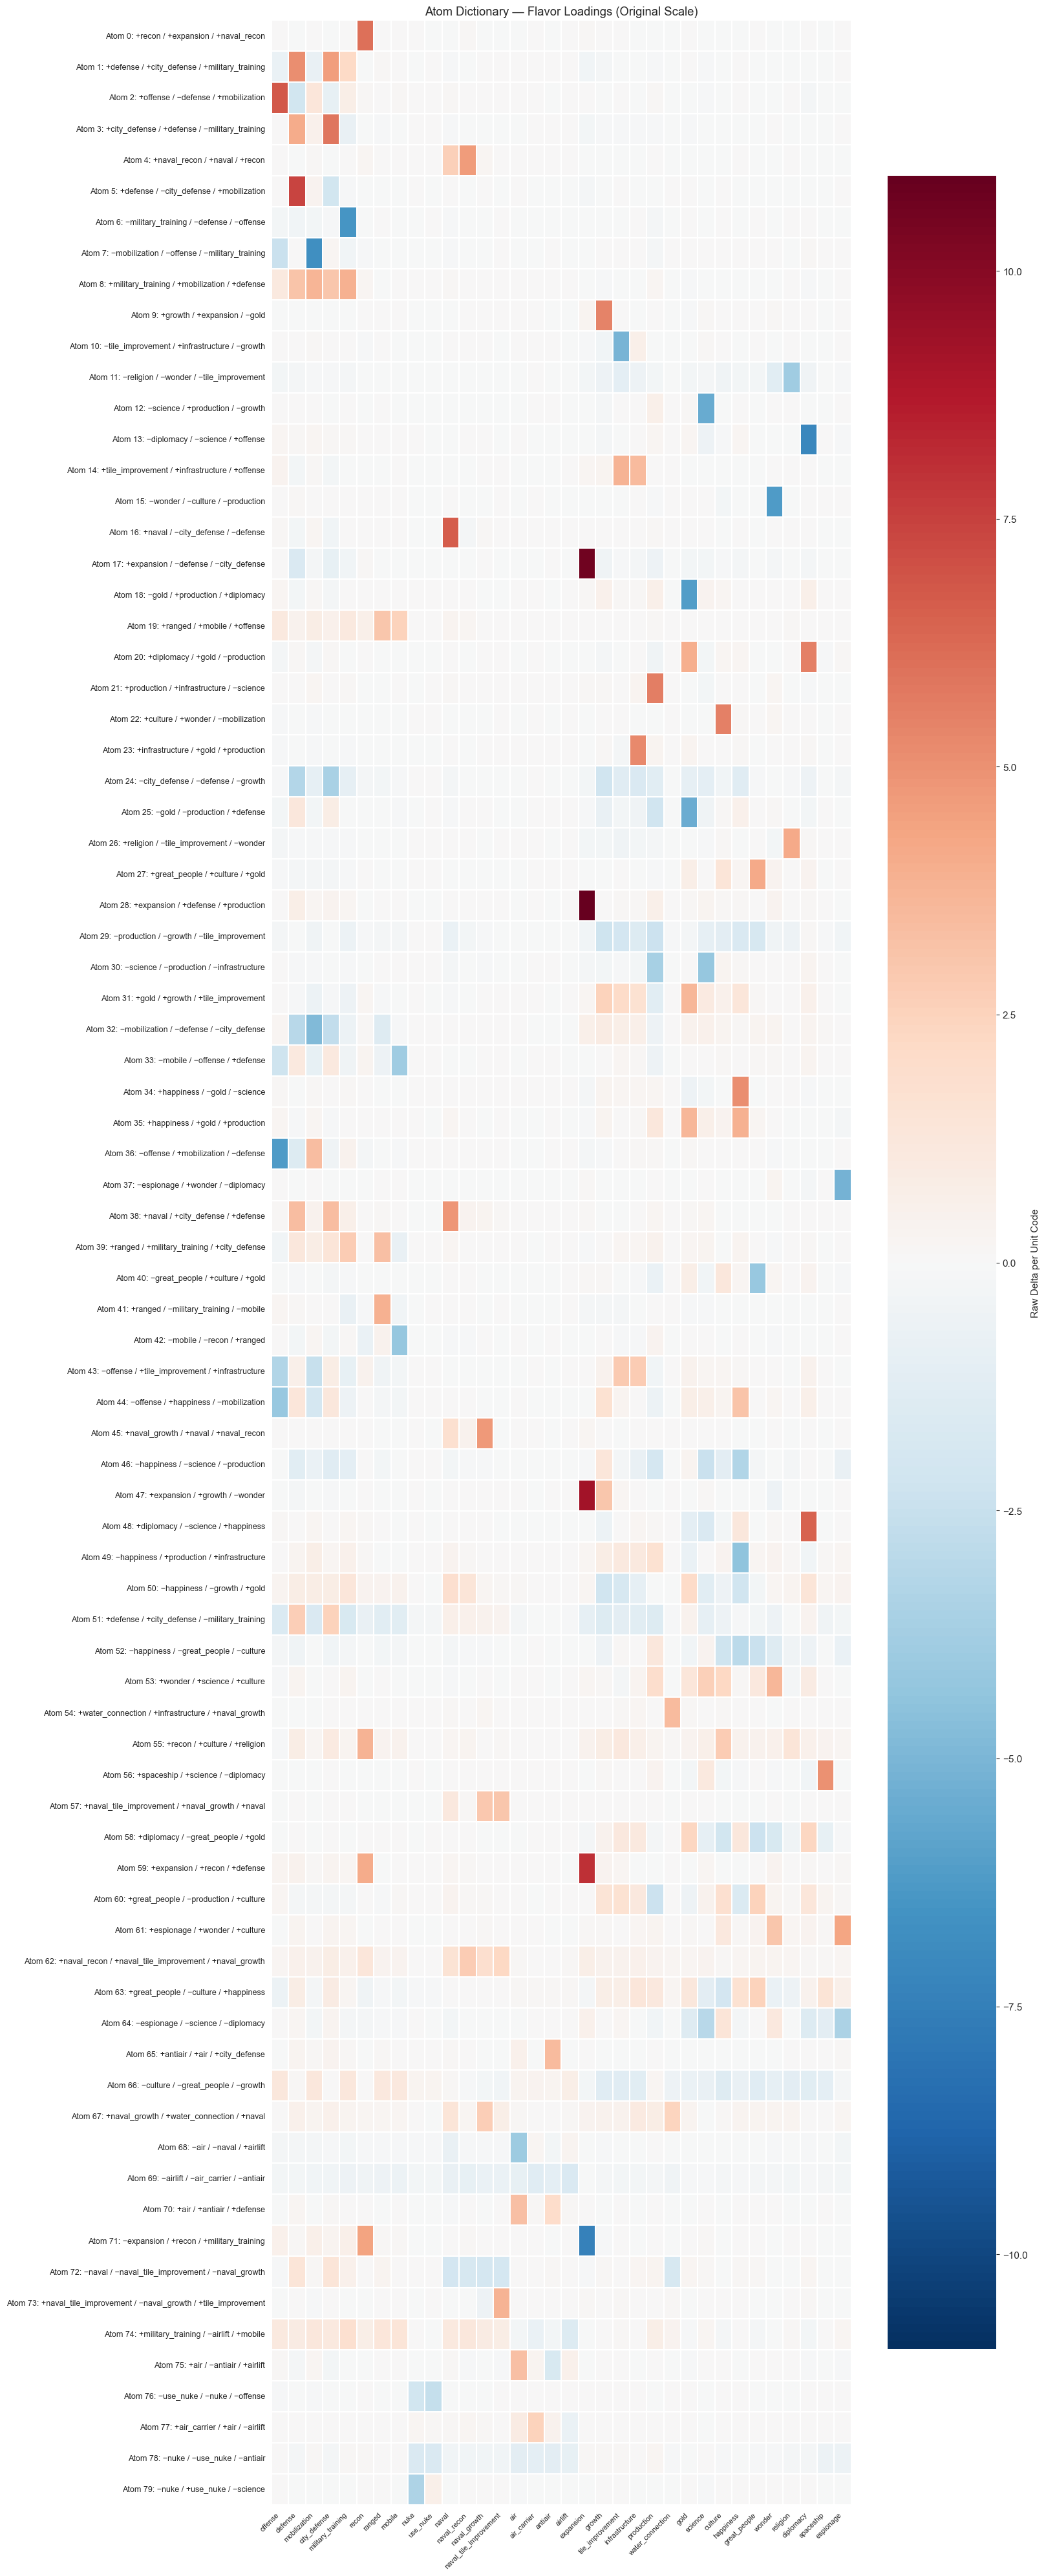

In [26]:
# --- Atom heatmap: (K × 34) with diverging colormap ---
atoms_display = pd.DataFrame(
    atoms_orig,
    index=[f"Atom {k}: {atom_names[k]}" for k in range(K_CHOSEN)],
    columns=flavor_short,
)

vmax = np.abs(atoms_orig).max()
fig, ax = plt.subplots(figsize=(16, max(6, K_CHOSEN * 0.5)))
sns.heatmap(
    atoms_display,
    cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
    linewidths=0.3, ax=ax,
    cbar_kws={"label": "Raw Delta per Unit Code"},
)
ax.set_title("Atom Dictionary — Flavor Loadings (Original Scale)")
plt.xticks(rotation=45, ha="right", fontsize=8)
plt.yticks(fontsize=9, rotation=0)
plt.tight_layout()
plt.show()

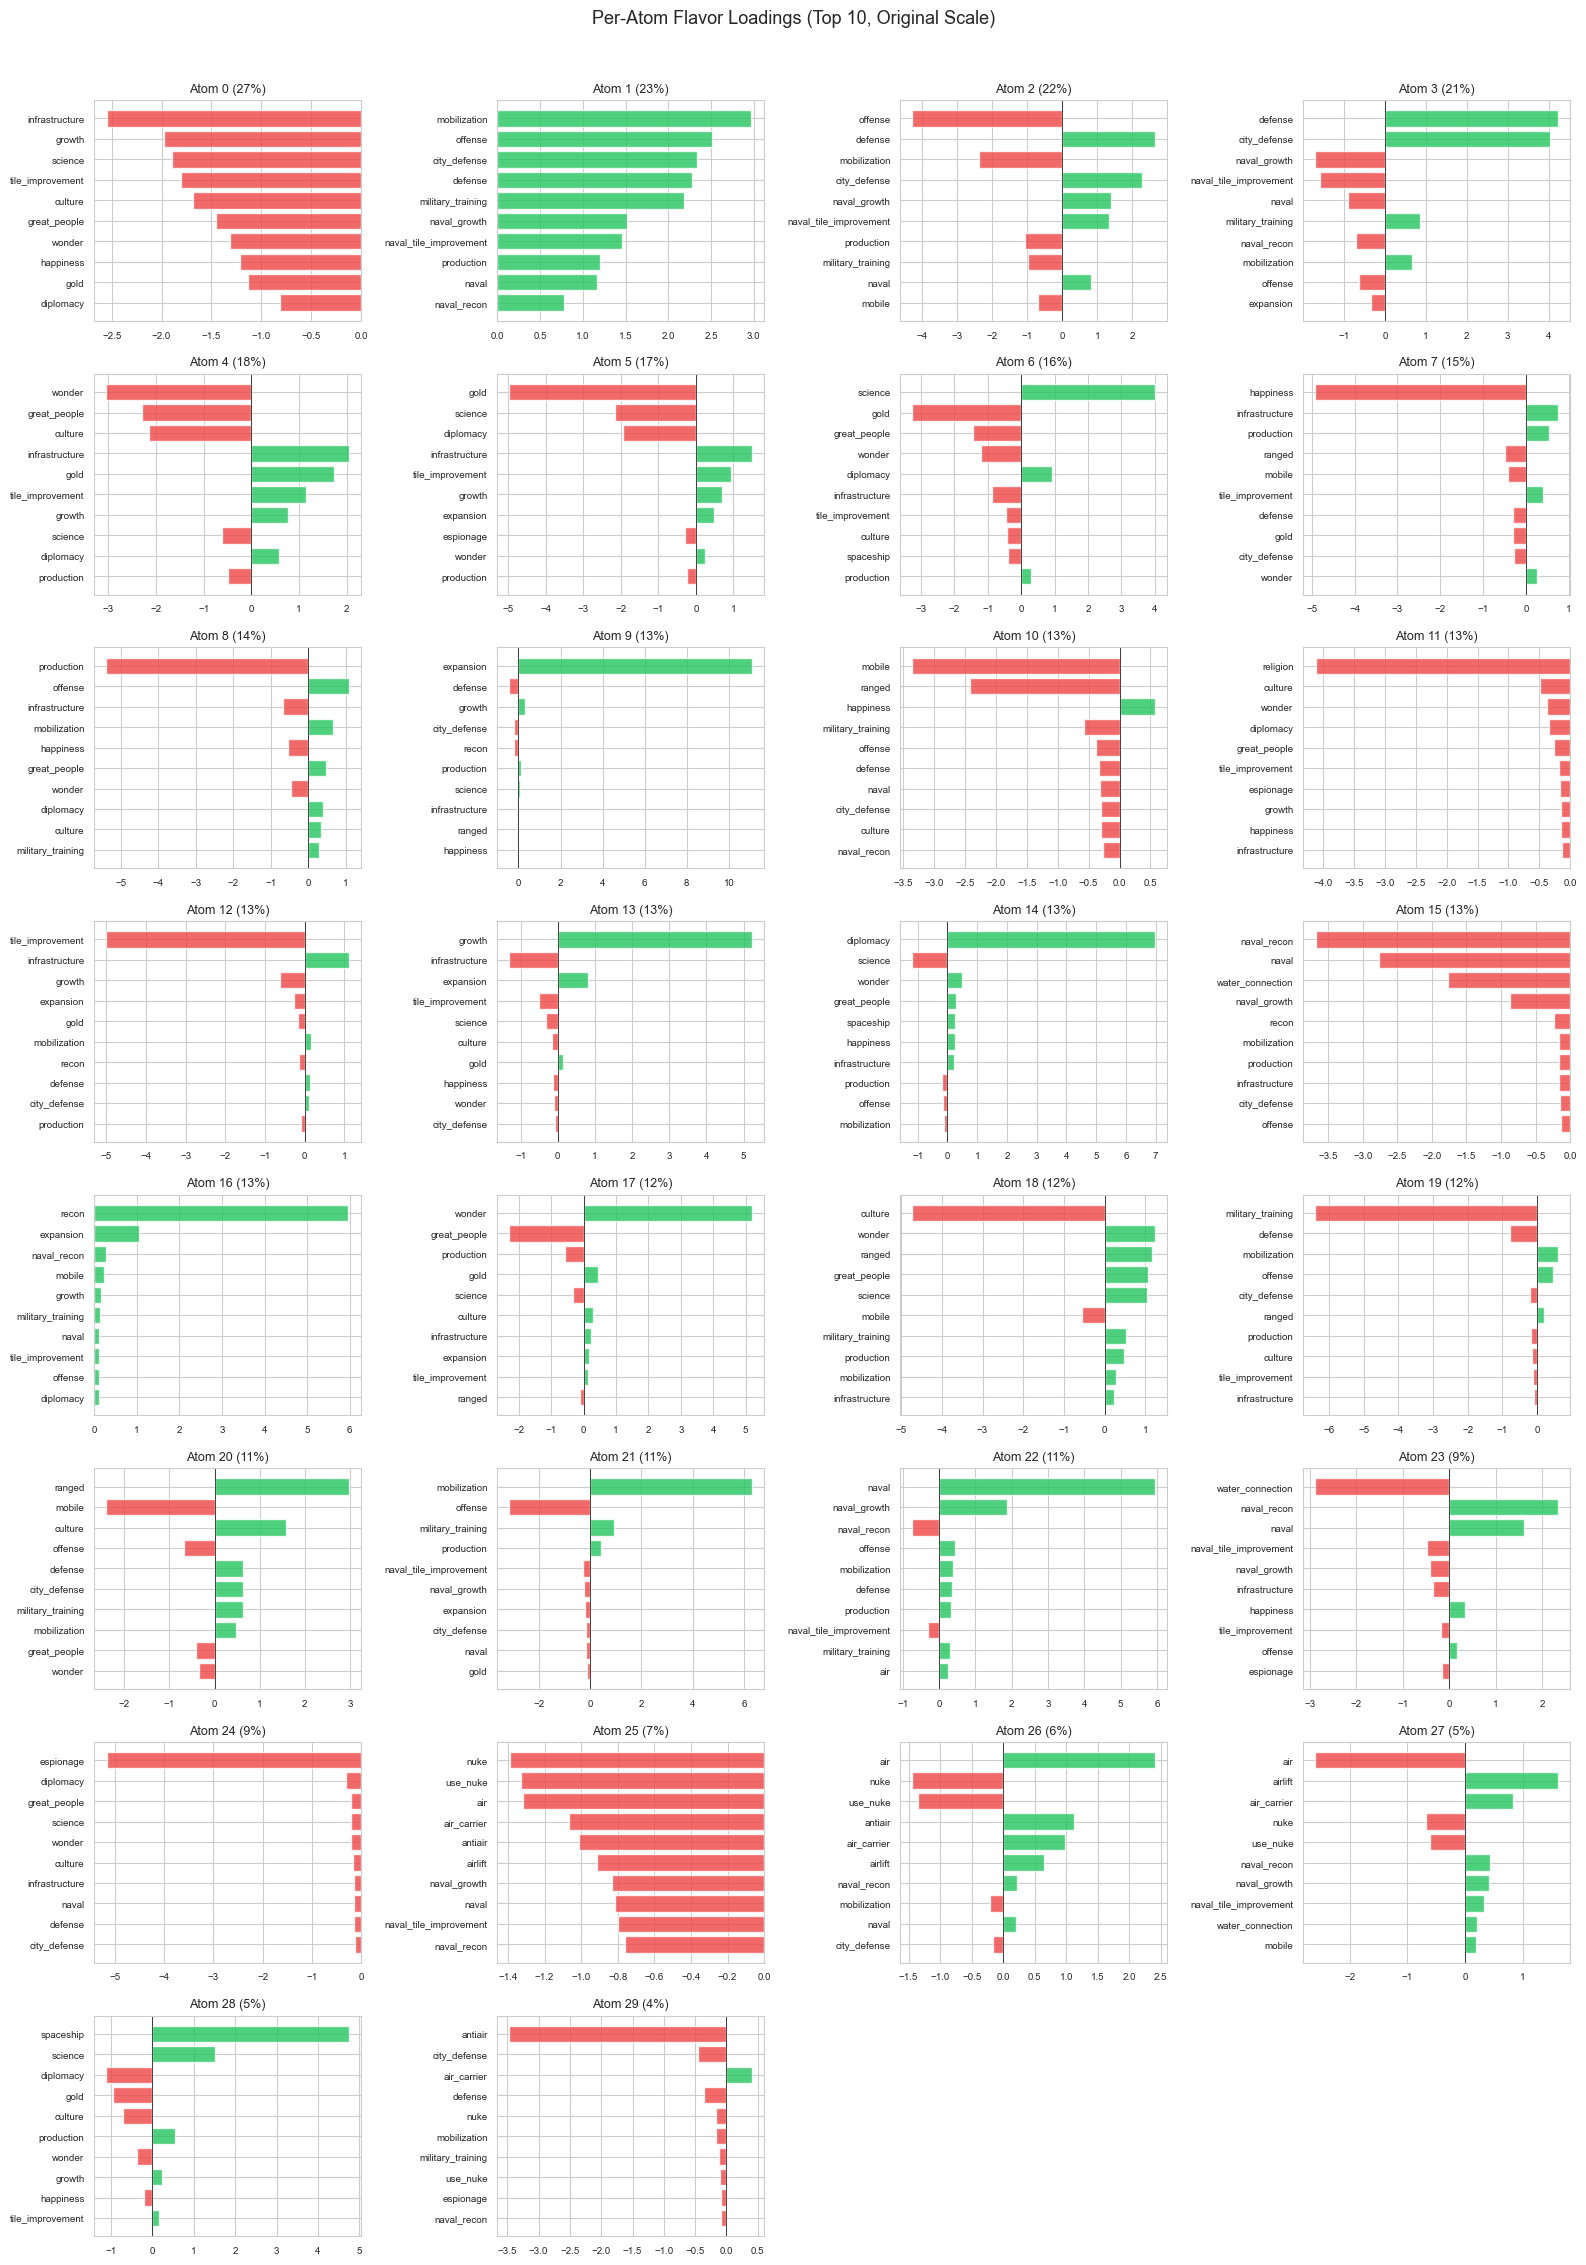

In [ ]:
# --- Per-atom bar charts: top 10 flavor loadings per atom ---
n_cols = 4
n_rows = int(np.ceil(K_CHOSEN / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 2.8))
axes = axes.flatten()

for k in range(K_CHOSEN):
    ax = axes[k]
    loadings = atoms_orig[k]
    top_idx = np.argsort(np.abs(loadings))[::-1][:10]
    vals = loadings[top_idx]
    names = [flavor_short[j] for j in top_idx]
    colors = ["#22C55E" if v > 0 else "#EF4444" for v in vals]
    ax.barh(range(len(names)), vals, color=colors, alpha=0.8)
    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(names, fontsize=7)
    ax.invert_yaxis()
    ax.axvline(0, color="black", lw=0.5)
    ax.set_title(f"Atom {k} ({activation_freq[k]:.0%})", fontsize=9)
    ax.tick_params(axis="x", labelsize=7)

# Hide unused subplots
for i in range(K_CHOSEN, len(axes)):
    axes[i].set_visible(False)

fig.suptitle("Per-Atom Flavor Loadings (Top 10, Original Scale)", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

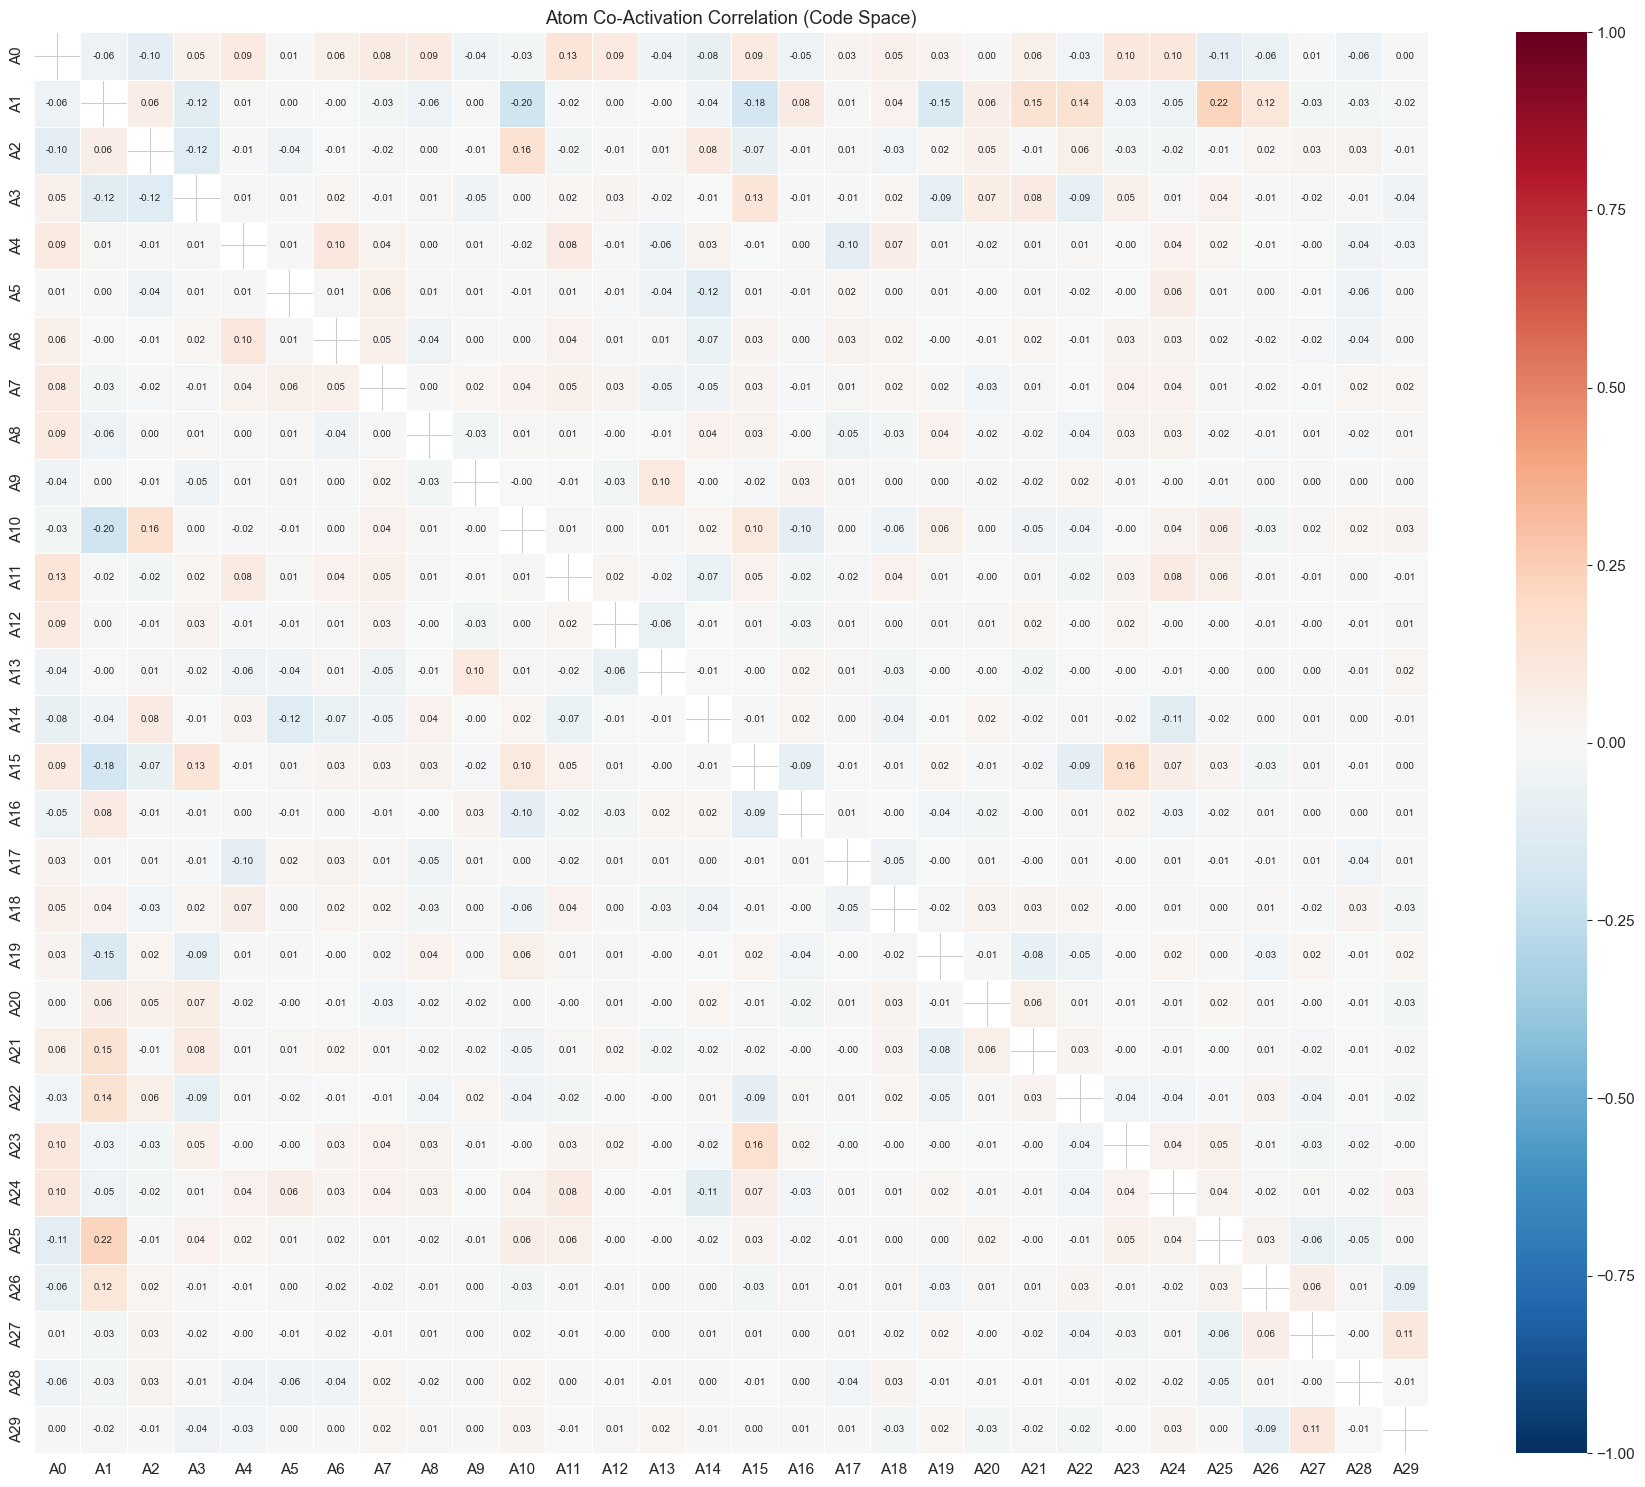

No strong co-activations (|r| > 0.3) — atoms are largely independent.


In [ ]:
# --- Atom co-activation correlation ---
# Do certain atoms tend to fire together? Ideally mostly near-zero.
code_corr = np.corrcoef(codes.T)  # (K, K)

fig, ax = plt.subplots(figsize=(max(8, K_CHOSEN * 0.6), max(7, K_CHOSEN * 0.5)))
labels = [f"A{k}" for k in range(K_CHOSEN)]
mask = np.eye(K_CHOSEN, dtype=bool)
sns.heatmap(
    code_corr,
    xticklabels=labels, yticklabels=labels,
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    annot=True, fmt=".2f", annot_kws={"size": 7},
    mask=mask, linewidths=0.5, ax=ax,
)
ax.set_title("Atom Co-Activation Correlation (Code Space)")
plt.tight_layout()
plt.show()

# Flag strong correlations
strong = []
for i in range(K_CHOSEN):
    for j in range(i + 1, K_CHOSEN):
        if abs(code_corr[i, j]) > 0.3:
            strong.append((i, j, code_corr[i, j]))
if strong:
    print("Atom pairs with |correlation| > 0.3:")
    for i, j, r in sorted(strong, key=lambda x: -abs(x[2])):
        print(f"  Atom {i} ↔ Atom {j}: r = {r:+.3f}")
else:
    print("No strong co-activations (|r| > 0.3) — atoms are largely independent.")

## Section 4: Export

Export atom dictionary and per-event sparse codes for downstream analysis
in `flavor_change_effects.ipynb`. The export mirrors the structure of
`flavor_change_clusters/` so the effects notebook can consume it with
minimal changes.

In [ ]:
import os
os.makedirs("flavor_change_decomposition", exist_ok=True)

# --- CSV A: per-event data with atom codes and UMAP coordinates ---
import umap

# UMAP on code space for visualization
reducer = umap.UMAP(n_components=2, metric="cosine", random_state=42)
X_umap = reducer.fit_transform(codes)

export_cols = [
    "game_id", "player_id", "turn", "max_turn", "n_flavors_changed",
    "player_type", "strategy_filled",
    "before_prob", "after_prob", "win_prob_delta", "impact_class",
]
events = multi[export_cols].copy()
events["turn_progress"] = events["turn"] / events["max_turn"]
events["dominant_atom"] = np.argmax(np.abs(codes), axis=1)
events["n_active_atoms"] = (np.abs(codes) >= 1e-6).sum(axis=1)
for k in range(K_CHOSEN):
    events[f"atom_{k}_code"] = codes[:, k]
events["umap_x"] = X_umap[:, 0]
events["umap_y"] = X_umap[:, 1]
events.to_csv("flavor_change_decomposition/multi_flavor_events.csv", index=False)
print(f"Exported {len(events):,} events → flavor_change_decomposition/multi_flavor_events.csv")

# --- CSV B: atom dictionary (mirrors cluster_profiles.csv structure) ---
atom_df = pd.DataFrame(atoms_orig, columns=delta_cols)
atom_df.index.name = "atom"
atom_df["atom_name"] = atom_names
atom_df["activation_frequency"] = activation_freq
atom_df["mean_activation"] = [
    np.abs(codes[np.abs(codes[:, k]) >= 1e-6, k]).mean()
    if (np.abs(codes[:, k]) >= 1e-6).any() else 0.0
    for k in range(K_CHOSEN)
]
# Mean win_prob_delta when this atom is dominant
dom = np.argmax(np.abs(codes), axis=1)
wpd = multi["win_prob_delta"].values
atom_df["mean_win_prob_delta"] = [
    np.nanmean(wpd[dom == k]) if (dom == k).any() else np.nan
    for k in range(K_CHOSEN)
]
atom_df["size"] = [(dom == k).sum() for k in range(K_CHOSEN)]
# Top flavors string (same format as cluster_profiles.csv)
top_flavors_list = []
for k in range(K_CHOSEN):
    top = pd.Series(atoms_orig[k], index=delta_cols).abs().nlargest(8)
    top_flavors_list.append(", ".join(
        f"{idx.replace('flavor_', '').replace('_delta', '')} "
        f"({'+'if atoms_orig[k][delta_cols.index(idx)] > 0 else ''}"
        f"{atoms_orig[k][delta_cols.index(idx)]:.3f})"
        for idx in top.index
    ))
atom_df["top_flavors"] = top_flavors_list
atom_df.to_csv("flavor_change_decomposition/atom_dictionary.csv")
print(f"Exported {len(atom_df)} atom profiles → flavor_change_decomposition/atom_dictionary.csv")

# --- CSV C: scaler params for reproducibility ---
scaler_df = pd.DataFrame({
    "feature": delta_cols,
    "mean": scaler.mean_,
    "scale": scaler.scale_,
})
scaler_df.to_csv("flavor_change_decomposition/scaler_params.csv", index=False)
print(f"Exported scaler params → flavor_change_decomposition/scaler_params.csv")

c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


KeyboardInterrupt: 